# Implementasi dan Eksperimen PSO

Computational Intelligence - ITS
Maria Putu Evelyne Corena Puryatma (5054251011)

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ranksums

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

NOTEBOOK_START = time.time()
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.2.6 | pandas 2.3.3


## 1. Fungsi uji

Ada dua fungsi dengan karakter berlawanan:

- **Sphere**: `f(x) = sum(x_i^2)`. Hanya punya satu lembah, jadi mudah.
- **Rastrigin**: `f(x) = 10*D + sum(x_i^2 - 10*cos(2*pi*x_i))`. Punya banyak minimum lokal, jadi mudah terjebak.

Keduanya bernilai minimum 0 di x = 0, dengan ruang cari [-5,12; 5,12] pada D = 10. Input fungsi berbentuk `(N, D)` dan dijumlahkan di sumbu terakhir, sehingga semua partikel dihitung sekaligus.

In [2]:
D = 10
BOUNDS = (-5.12, 5.12)


def sphere(x):
    # x: shape (D,) or (N, D). Sum over the last axis -> one value per particle.
    return np.sum(x**2, axis=-1)


def rastrigin(x):
    d = x.shape[-1]
    return 10 * d + np.sum(x**2 - 10 * np.cos(2 * np.pi * x), axis=-1)


FUNCTIONS = {"Sphere": sphere, "Rastrigin": rastrigin}

# Sanity check: both functions have their minimum f = 0 at x = 0.
for name, func in FUNCTIONS.items():
    value = func(np.zeros(D))
    print(f"{name:9s} f(0) = {value}")
    assert value == 0

# Vectorization check: 3 particles evaluated in one call.
print("Sphere untuk 3 partikel sekaligus:", sphere(np.ones((3, D))))

Sphere    f(0) = 0.0
Rastrigin f(0) = 0.0
Sphere untuk 3 partikel sekaligus: [10. 10. 10.]


## 2. Implementasi gbest PSO

Tiap partikel menyimpan posisi x, kecepatan v, dan posisi terbaiknya sendiri (pbest). Semua partikel juga tahu posisi terbaik seluruh swarm (gbest).

Mode inersia:

```
v = w*v + c1*r1*(pbest - x) + c2*r2*(gbest - x)
x = x + v
```

Mode constriction:

```
v = chi * (v + c1*r1*(pbest - x) + c2*r2*(gbest - x))
```

Suku pertama menjaga arah gerak, suku kedua menarik ke pbest, dan suku ketiga menarik ke gbest. r1 dan r2 acak U(0,1) untuk tiap partikel, dimensi, dan iterasi.

Detail yang dipakai:
- posisi awal uniform di [-5,12; 5,12], kecepatan awal 0
- kecepatan dibatasi |v| <= Vmax = 0,2 * 10,24 = 2,048
- posisi yang keluar batas dipotong ke batas, kecepatan dimensi itu jadi 0
- update sinkron: semua partikel bergerak dulu, baru pbest dan gbest diperbarui
- konfigurasi B: `w(t) = 0,9 - 0,5*t/T` dengan t = 0 sampai T-1
- diversitas = rata-rata jarak partikel ke titik tengah swarm (besar = menyebar, kecil = berkumpul)

Semua partikel disimpan sebagai matriks `(N, D)`, jadi hanya iterasi yang di-loop. `gbest_x` berbentuk `(D,)` dan `gbest_x - x` otomatis berlaku ke semua baris lewat broadcasting.

In [3]:
def pso(func, D, bounds, N, T, mode="fixed", w=0.7, w_start=0.9, w_end=0.4,
        c1=1.5, c2=1.5, chi=None, seed=0):
    # gbest PSO for minimization.
    # mode = "fixed"        -> constant inertia w
    #        "linear"       -> inertia decreases linearly from w_start to w_end
    #        "constriction" -> constriction factor chi (Clerc & Kennedy)
    rng = np.random.default_rng(seed)
    lower, upper = bounds
    vmax = 0.2 * (upper - lower)

    # Initialization
    x = rng.uniform(lower, upper, size=(N, D))
    v = np.zeros((N, D))
    pbest_x = x.copy()
    pbest_f = func(x)
    best = np.argmin(pbest_f)
    gbest_x = pbest_x[best].copy()
    gbest_f = pbest_f[best]

    history = np.empty(T)     # gbest fitness after every iteration
    diversity = np.empty(T)   # mean distance to the swarm centroid

    for t in range(T):
        r1 = rng.random((N, D))   # fresh per particle, per dimension, per iteration
        r2 = rng.random((N, D))
        cognitive = c1 * r1 * (pbest_x - x)
        social = c2 * r2 * (gbest_x - x)

        if mode == "constriction":
            v = chi * (v + cognitive + social)
        else:
            w_t = w if mode == "fixed" else w_start - (w_start - w_end) * t / T
            v = w_t * v + cognitive + social

        v = np.clip(v, -vmax, vmax)            # velocity clamping
        x = x + v

        outside = (x < lower) | (x > upper)    # boundary handling
        x = np.clip(x, lower, upper)
        v[outside] = 0.0

        # Synchronous update: evaluate after ALL particles have moved
        f = func(x)
        improved = f < pbest_f
        pbest_x[improved] = x[improved]
        pbest_f[improved] = f[improved]
        best = np.argmin(pbest_f)
        gbest_x = pbest_x[best].copy()
        gbest_f = pbest_f[best]

        history[t] = gbest_f
        diversity[t] = np.mean(np.linalg.norm(x - x.mean(axis=0), axis=1))

    return gbest_x, float(gbest_f), history, diversity

### Tes awal: 1 run Sphere (konfigurasi A)

Coba sekali dulu dengan w = 0,7 dan c1 = c2 = 1,5.

gbest_f = 2.247e-57   (waktu 0.02 detik)
gbest_x = [ 0. -0. -0.  0.  0.  0.  0.  0. -0. -0.]
panjang history = 1000 | history tidak pernah naik? True
diversitas iterasi 1 = 6.285 | iterasi 1000 = 2.459e-28


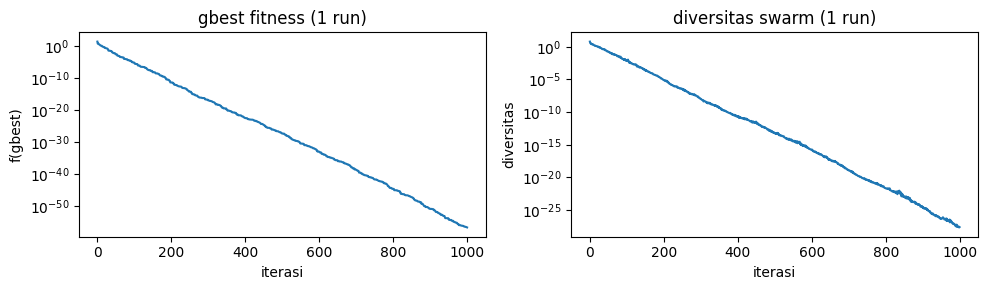

In [4]:
start = time.time()
x_best, f_best, hist, div = pso(sphere, D, BOUNDS, N=30, T=1000,
                                mode="fixed", w=0.7, c1=1.5, c2=1.5, seed=0)
print(f"gbest_f = {f_best:.3e}   (waktu {time.time() - start:.2f} detik)")
print("gbest_x =", np.round(x_best, 6))
print("panjang history =", len(hist), "| history tidak pernah naik?", bool(np.all(np.diff(hist) <= 0)))
print(f"diversitas iterasi 1 = {div[0]:.3f} | iterasi 1000 = {div[-1]:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].semilogy(hist)
axes[0].set(title="gbest fitness (1 run)", xlabel="iterasi", ylabel="f(gbest)")
axes[1].semilogy(div)
axes[1].set(title="diversitas swarm (1 run)", xlabel="iterasi", ylabel="diversitas")
plt.tight_layout()
plt.show()

gbest_f sekitar 2e-57 (praktis 0) dan gbest_x hampir 0. History tidak pernah naik (wajar, gbest hanya diganti kalau ada yang lebih baik). Diversitas turun dari sekitar 6,3 ke 1e-28, artinya swarm sudah berkumpul. Implementasi benar.

## 3. Konfigurasi eksperimen

Semua konfigurasi memakai N = 30, T = 1000, dan 30 run dengan seed 0-29. Seed sama di semua konfigurasi, jadi run ke-k selalu mulai dari posisi awal yang sama dan hanya parameternya yang berbeda.

| Konfigurasi | Parameter |
|---|---|
| A | w = 0,7 tetap, c1 = c2 = 1,5 |
| B | w turun linear 0,9 ke 0,4, c1 = c2 = 2,0 |
| C | constriction chi = 0,7298, c1 = c2 = 2,05 |

Nilai chi dihitung dari rumus Clerc & Kennedy dengan phi = c1 + c2 = 4,1:

```
chi = 2 / |2 - phi - sqrt(phi^2 - 4*phi)|
```

In [5]:
N = 30
T = 1000
RUNS = 30
SEEDS = range(RUNS)   # the same seeds 0..29 for every configuration

phi = 2.05 + 2.05
chi = 2 / abs(2 - phi - np.sqrt(phi**2 - 4 * phi))
print(f"chi = {chi:.6f}")
print(f"chi * c = {chi * 2.05:.4f}  (koefisien akselerasi efektif konfigurasi C)")

CONFIGS = {
    "A": dict(mode="fixed", w=0.7, c1=1.5, c2=1.5),
    "B": dict(mode="linear", w_start=0.9, w_end=0.4, c1=2.0, c2=2.0),
    "C": dict(mode="constriction", chi=chi, c1=2.05, c2=2.05),
}

chi = 0.729844
chi * c = 1.4962  (koefisien akselerasi efektif konfigurasi C)


## 4. Menjalankan eksperimen

Totalnya 3 x 2 x 30 = 180 run. Untuk tiap fungsi dan konfigurasi disimpan fitness akhir (30 nilai), history gbest (30 x 1000), dan diversitas (30 x 1000). Fitness akhir juga ditulis ke `hasil_final_fitness.csv`.

In [6]:
results = {}
start = time.time()

for f_name, func in FUNCTIONS.items():
    for c_name, params in CONFIGS.items():
        finals, histories, diversities = [], [], []
        for seed in SEEDS:
            _, f_best, hist, div = pso(func, D, BOUNDS, N, T, seed=seed, **params)
            finals.append(f_best)
            histories.append(hist)
            diversities.append(div)
        results[(f_name, c_name)] = {
            "final": np.array(finals),
            "history": np.array(histories),
            "diversity": np.array(diversities),
        }

print(f"{len(results)} kombinasi x {RUNS} run selesai dalam {time.time() - start:.1f} detik")

final_df = pd.DataFrame({f"{f}-{c}": res["final"] for (f, c), res in results.items()})
final_df.index.name = "seed"
final_df.to_csv("hasil_final_fitness.csv")
final_df.head()

6 kombinasi x 30 run selesai dalam 3.8 detik


,Sphere-A,Sphere-B,Sphere-C,Rastrigin-A,Rastrigin-B,Rastrigin-C
seed,,,,,,
0,2.246647e-57,1.455495e-27,1.880106e-49,3.979836,1.990489,3.979836
1,2.739774e-58,2.875669e-26,6.844358e-51,8.954626,2.047454,7.959667
2,3.440735e-58,4.564863e-28,7.639494e-49,12.934458,3.979836,3.979836
3,9.846395e-60,6.263331e-26,3.213095e-49,9.949580,2.984877,8.954626
4,1.036090e-57,5.399829e-27,6.291280e-48,8.954626,2.984877,11.939499


## 5. Analisis

### 5.1 Statistik fitness akhir dan success rate

Success rate adalah persen run yang mencapai f < 1e-6 (Sphere) atau f < 10 (Rastrigin). Mean iter. sukses adalah rata-rata iterasi pertama saat gbest melewati ambang, dihitung hanya dari run yang berhasil.

In [7]:
THRESHOLDS = {"Sphere": 1e-6, "Rastrigin": 10.0}


def first_hit(history, threshold):
    # 1-based iteration where gbest first drops below the threshold (None if never).
    below = np.flatnonzero(history < threshold)
    return below[0] + 1 if below.size > 0 else None


rows = []
for (f_name, c_name), res in results.items():
    final = res["final"]
    hits = [first_hit(h, THRESHOLDS[f_name]) for h in res["history"]]
    hits = [h for h in hits if h is not None]
    rows.append({
        "Fungsi": f_name,
        "Konfigurasi": c_name,
        "Mean": final.mean(),
        "Std": final.std(ddof=1),
        "Median": np.median(final),
        "Best": final.min(),
        "Worst": final.max(),
        "Success rate (%)": 100 * len(hits) / len(final),
        "Mean iter. sukses": np.mean(hits) if hits else np.nan,
    })
summary = pd.DataFrame(rows)

# Readable version: scientific notation for fitness values
table = pd.DataFrame({
    "Fungsi": summary["Fungsi"],
    "Konfigurasi": summary["Konfigurasi"],
    "Mean +/- Std": [f"{m:.3e} +/- {s:.3e}" for m, s in zip(summary["Mean"], summary["Std"])],
    "Median": summary["Median"].map("{:.3e}".format),
    "Best": summary["Best"].map("{:.3e}".format),
    "Worst": summary["Worst"].map("{:.3e}".format),
    "Success rate (%)": summary["Success rate (%)"].map("{:.1f}".format),
    "Mean iter. sukses": summary["Mean iter. sukses"].map("{:.1f}".format),
})
table

,Fungsi,Konfigurasi,Mean +/- Std,Median,Best,Worst,Success rate (%),Mean iter. sukses
0,Sphere,A,4.254e-58 +/- 7.667e-58,4.475e-59,1.488e-61,2.647e-57,100.0,109.6
1,Sphere,B,1.960e-26 +/- 4.251e-26,2.253e-27,1.560e-29,2.040e-25,100.0,587.3
2,Sphere,C,3.248e-48 +/- 8.791e-48,5.978e-49,5.372e-52,3.523e-47,100.0,128.9
3,Rastrigin,A,1.005e+01 +/- 4.891e+00,8.955e+00,1.990e+00,2.388e+01,63.3,111.8
4,Rastrigin,B,3.225e+00 +/- 1.771e+00,2.985e+00,1.020e-11,8.955e+00,100.0,461.6
5,Rastrigin,C,7.661e+00 +/- 4.108e+00,6.965e+00,1.990e+00,1.990e+01,83.3,91.8


**Sphere.** Semua konfigurasi sukses 100%. Median A 4,5e-59, C 6,0e-49, B 2,3e-27. Semuanya sudah jauh di bawah ambang, jadi yang lebih menentukan adalah kecepatan: A sampai ambang di iterasi 110, C di 129, B baru di 587.

**Rastrigin.** Urutannya terbalik. B terbaik dengan mean 3,23 dan sukses 100% (satu run bahkan sampai optimum global), lalu C sukses 83% dan A 63%. B paling lambat mencapai ambang (iterasi 462), sedangkan A dan C cepat (112 dan 92) tetapi lalu berhenti membaik.

Nilai akhir Rastrigin banyak berupa kelipatan sekitar 0,995 (1,99; 2,98; 3,98; 8,96). Minimum lokalnya ada dekat bilangan bulat, dan tiap koordinat yang tersangkut di 1 atau -1 menambah sekitar 0,995 ke fitness. Jadi median A = 8,96 berarti sekitar 9 koordinat yang tersangkut.

### 5.2 Grafik konvergensi dan diversitas

Grafik atas menunjukkan rata-rata fitness gbest (skala log), grafik bawah rata-rata diversitas. Pita adalah persentil 25-75 dari 30 run dan garis putus-putus adalah ambang sukses.

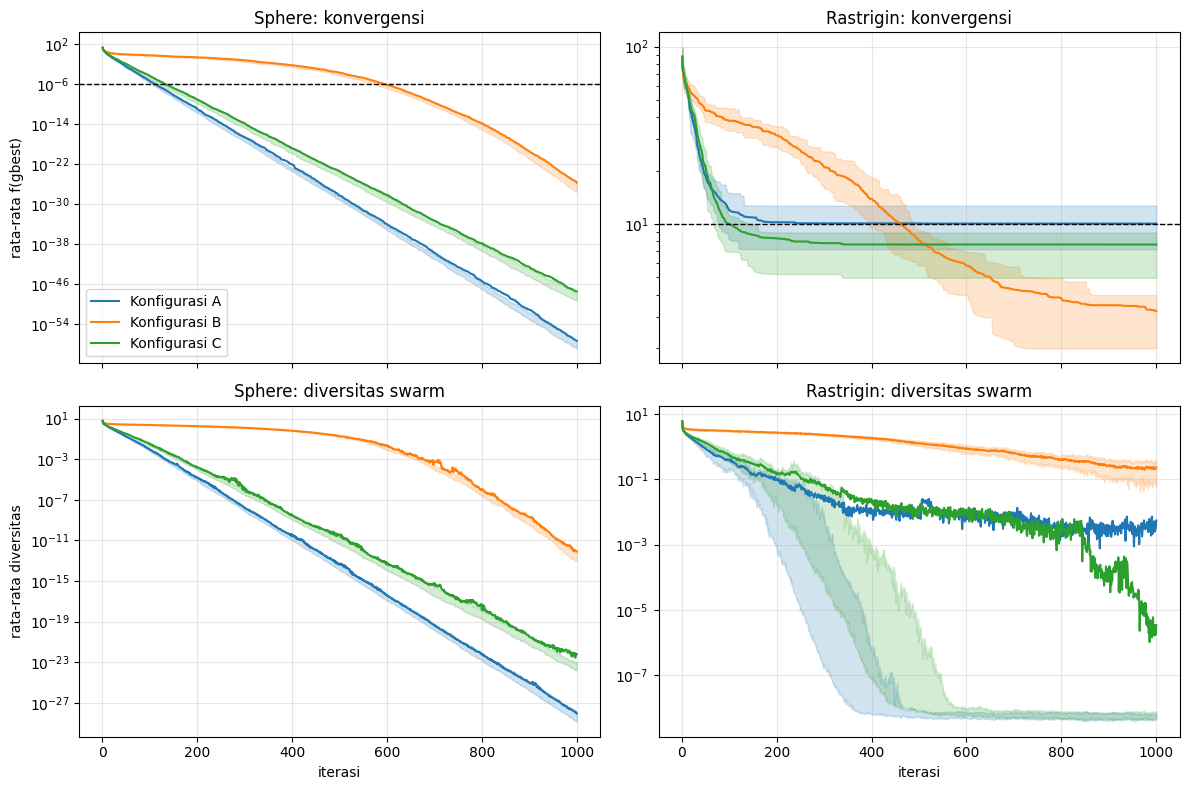

In [8]:
COLORS = {"A": "tab:blue", "B": "tab:orange", "C": "tab:green"}
iterations = np.arange(1, T + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for col, f_name in enumerate(FUNCTIONS):
    for row, key in enumerate(["history", "diversity"]):
        ax = axes[row, col]
        for c_name in CONFIGS:
            data = results[(f_name, c_name)][key]          # shape (RUNS, T)
            q25, q75 = np.percentile(data, [25, 75], axis=0)
            ax.plot(iterations, data.mean(axis=0), color=COLORS[c_name], label=f"Konfigurasi {c_name}")
            ax.fill_between(iterations, q25, q75, color=COLORS[c_name], alpha=0.2)
        ax.set_yscale("log")
        ax.grid(alpha=0.3)
    axes[0, col].axhline(THRESHOLDS[f_name], color="black", linestyle="--", linewidth=1)
    axes[0, col].set_title(f"{f_name}: konvergensi")
    axes[1, col].set_title(f"{f_name}: diversitas swarm")
    axes[1, col].set_xlabel("iterasi")
axes[0, 0].set_ylabel("rata-rata f(gbest)")
axes[1, 0].set_ylabel("rata-rata diversitas")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "konvergensi_diversitas.png", dpi=150)
plt.show()

Angka dari grafik. Median diversitas ikut ditampilkan karena rata-rata mudah tertarik oleh beberapa run ekstrem.

In [9]:
rows = []
for (f_name, c_name), res in results.items():
    mean_hist = res["history"].mean(axis=0)
    div = res["diversity"]
    rows.append({
        "Fungsi": f_name,
        "Konfigurasi": c_name,
        "f iter 100": mean_hist[99],
        "f iter 200": mean_hist[199],
        "f iter 500": mean_hist[499],
        "f iter 1000": mean_hist[-1],
        "div iter 400 (mean)": div[:, 399].mean(),
        "div iter 1000 (mean)": div[:, -1].mean(),
        "div iter 1000 (median)": np.median(div[:, -1]),
    })
support = pd.DataFrame(rows)
for col in support.columns[2:]:                  # scientific notation for all numeric columns
    support[col] = support[col].map("{:.2e}".format)
support

,Fungsi,Konfigurasi,f iter 100,f iter 200,f iter 500,f iter 1000,div iter 400 (mean),div iter 1000 (mean),div iter 1000 (median)
0,Sphere,A,4.74e-06,1.27e-11,5.15e-29,4.25e-58,2.59e-11,8.77e-29,2.94e-29
1,Sphere,B,6.16e-01,2.39e-01,2.01e-04,1.96e-26,6.22e-01,8.22e-13,2.18e-13
2,Sphere,C,5.07e-05,8.64e-10,3.84e-24,3.25e-48,3.40e-09,6.12e-23,4.95e-24
3,Rastrigin,A,1.20e+01,1.02e+01,1.01e+01,1.00e+01,9.86e-03,5.50e-03,5.12e-09
4,Rastrigin,B,3.81e+01,3.15e+01,8.04e+00,3.22e+00,1.90e+00,2.32e-01,1.82e-01
5,Rastrigin,C,1.00e+01,8.31e+00,7.66e+00,7.66e+00,2.07e-02,3.38e-06,6.22e-09


Untuk Rastrigin, dicek juga kapan terakhir kali gbest membaik lebih dari 0,5 (kira-kira setengah jarak antar minimum lokal, yaitu 0,995).

In [10]:
def last_big_improvement(history, min_gain=0.5):
    # 1-based iteration of the last gbest improvement larger than min_gain.
    gains = history[:-1] - history[1:]
    big = np.flatnonzero(gains > min_gain)
    return big[-1] + 2 if big.size > 0 else 1


for c_name in CONFIGS:
    histories = results[("Rastrigin", c_name)]["history"]
    last_iters = [last_big_improvement(h) for h in histories]
    still_improving = np.sum(histories[:, 199] - histories[:, -1] > 0.5)
    print(f"Konfigurasi {c_name}: median iterasi perbaikan besar terakhir = {np.median(last_iters):6.1f} | "
          f"run yang masih membaik > 0,5 setelah iterasi 200 = {still_improving} dari {RUNS}")

Konfigurasi A: median iterasi perbaikan besar terakhir =   89.5 | run yang masih membaik > 0,5 setelah iterasi 200 = 3 dari 30
Konfigurasi B: median iterasi perbaikan besar terakhir =  618.0 | run yang masih membaik > 0,5 setelah iterasi 200 = 30 dari 30
Konfigurasi C: median iterasi perbaikan besar terakhir =  111.0 | run yang masih membaik > 0,5 setelah iterasi 200 = 8 dari 30


**Sphere.** Garis A dan C hampir lurus di skala log, artinya fitness turun dengan laju tetap. A lebih curam (turun sekitar 59 orde dalam 1000 iterasi, C sekitar 49). B jauh lebih lambat: di iterasi 500 baru 2e-4, sedangkan A sudah 5e-29. Grafik diversitas menjelaskan sebabnya. B mulai dengan w = 0,9 sehingga partikelnya masih menyebar (iterasi 400: B 0,6, A 3e-11), dan baru konvergen cepat setelah w turun di bawah 0,6 (iterasi 600-an).

**Rastrigin.** A dan C turun cepat ke sekitar 10 dalam 100 iterasi pertama, lalu hampir datar (iterasi 200 ke 1000: A 10,2 ke 10,0; C 8,3 ke 7,7). Perbaikan besar terakhir (lebih dari 0,5) terjadi sekitar iterasi 90 untuk A dan 111 untuk C. Diversitas jatuh ke sekitar 5e-9, artinya di kebanyakan run swarm sudah terkunci di satu minimum lokal. Rata-rata diversitas A tampak di atas pitanya karena beberapa run masih bergerak.

B berbeda sendiri. Diversitasnya masih 1,9 di iterasi 400 dan 0,2 di akhir, dan fitness terus turun (31,5; 8,0; 3,2 di iterasi 200, 500, 1000). Semua 30 run B masih membaik setelah iterasi 200. Ini sesuai tujuan w yang turun linear: menjelajah dulu, memperhalus belakangan.

### 5.3 Boxplot fitness akhir

Sumbu y Sphere memakai skala log.

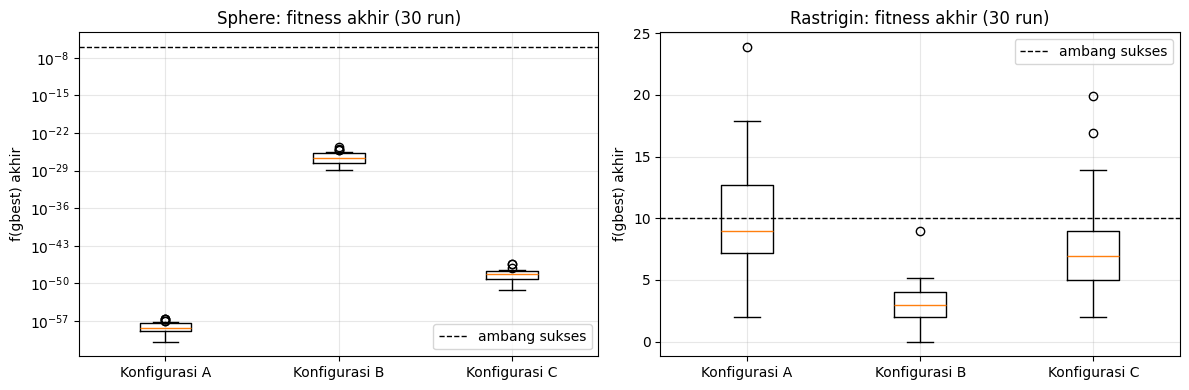

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, f_name in zip(axes, FUNCTIONS):
    data = [results[(f_name, c_name)]["final"] for c_name in CONFIGS]
    ax.boxplot(data)
    ax.set_xticks(range(1, len(CONFIGS) + 1), [f"Konfigurasi {c}" for c in CONFIGS])
    ax.axhline(THRESHOLDS[f_name], color="black", linestyle="--", linewidth=1, label="ambang sukses")
    ax.set_title(f"{f_name}: fitness akhir (30 run)")
    ax.set_ylabel("f(gbest) akhir")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_yscale("log")
plt.tight_layout()
plt.savefig(FIG_DIR / "boxplot.png", dpi=150)
plt.show()

Di Sphere ketiga box terpisah total dan semuanya jauh di bawah ambang. Di Rastrigin box B paling rendah dan paling sempit, jadi B lebih bagus sekaligus lebih konsisten. Box A paling lebar dan melewati garis ambang, sedangkan C di tengah dengan dua outlier (16,9 dan 19,9).

### 5.4 Uji Wilcoxon rank-sum

Fitness akhir antar konfigurasi dibandingkan dengan `scipy.stats.ranksums`. Jika p < 0,05, bedanya signifikan. Kolom terakhir menunjukkan konfigurasi dengan median lebih kecil (lebih bagus).

In [12]:
ALPHA = 0.05
PAIRS = [("A", "B"), ("A", "C"), ("B", "C")]

rows = []
for f_name in FUNCTIONS:
    for left, right in PAIRS:
        a = results[(f_name, left)]["final"]
        b = results[(f_name, right)]["final"]
        stat, p_value = ranksums(a, b)
        rows.append({
            "Fungsi": f_name,
            "Pasangan": f"{left} vs {right}",
            "Statistik z": round(stat, 3),
            "p-value": f"{p_value:.2e}",
            "Signifikan (alpha = 0,05)": "ya" if p_value < ALPHA else "tidak",
            "Median lebih kecil": left if np.median(a) < np.median(b) else right,
        })
wilcoxon_table = pd.DataFrame(rows)
wilcoxon_table

,Fungsi,Pasangan,Statistik z,p-value,"Signifikan (alpha = 0,05)",Median lebih kecil
0,Sphere,A vs B,-6.653,2.87e-11,ya,A
1,Sphere,A vs C,-6.653,2.87e-11,ya,A
2,Sphere,B vs C,6.653,2.87e-11,ya,C
3,Rastrigin,A vs B,5.552,2.83e-08,ya,B
4,Rastrigin,A vs C,2.225,2.61e-02,ya,C
5,Rastrigin,B vs C,-4.753,2.00e-06,ya,B


Semua pasangan punya p < 0,05. Di Sphere ketiga pasangan p = 2,9e-11 karena nilainya tidak tumpang tindih sama sekali, dengan urutan A < C < B. Di Rastrigin B jelas lebih bagus dari A dan C, sedangkan A vs C p = 0,026 (tipis). Dengan koreksi Bonferroni untuk 3 perbandingan (alpha jadi sekitar 0,017), A vs C tidak signifikan lagi.

Signifikan secara statistik belum tentu berarti secara praktis. Di Sphere A dan C beda sekitar 10 orde, tetapi keduanya sudah jauh di bawah ambang.

### 5.5 Apakah C sama dengan A?

Constriction sebenarnya bisa ditulis ulang sebagai PSO inersia:

```
chi*(v + c*r1*(pbest - x) + c*r2*(gbest - x))
   = chi*v + (chi*c)*r1*(pbest - x) + (chi*c)*r2*(gbest - x)
```

Jadi C setara dengan w = 0,7298 dan c = 0,7298 * 2,05 = 1,496. Konfigurasi A (w = 0,7; c = 1,5) hampir sama, hanya w-nya sedikit lebih kecil.

Dicek dua hal: apakah PSO inersia dengan w = chi dan c = 2,05*chi memberi hasil sama dengan C, dan seberapa beda A dengan C.

In [13]:
equiv_params = dict(mode="fixed", w=chi, c1=chi * 2.05, c2=chi * 2.05)

for f_name, func in FUNCTIONS.items():
    finals_equiv = np.array([pso(func, D, BOUNDS, N, T, seed=s, **equiv_params)[1] for s in SEEDS])
    finals_c = results[(f_name, "C")]["final"]
    finals_a = results[(f_name, "A")]["final"]
    print(f"{f_name}:")
    print(f"  median C (constriction)        = {np.median(finals_c):.4e}")
    print(f"  median inersia w=chi, c=chi*c  = {np.median(finals_equiv):.4e}")
    print(f"  run dengan nilai akhir sama     = {np.sum(np.isclose(finals_c, finals_equiv, rtol=1e-9, atol=0))} dari {RUNS} (selisih relatif < 1e-9)")
    print(f"  p-value C vs ekuivalennya      = {ranksums(finals_c, finals_equiv).pvalue:.3f}")
    print(f"  p-value A vs C                 = {ranksums(finals_a, finals_c).pvalue:.3e}")

Sphere:
  median C (constriction)        = 5.9779e-49
  median inersia w=chi, c=chi*c  = 4.7984e-49
  run dengan nilai akhir sama     = 0 dari 30 (selisih relatif < 1e-9)
  p-value C vs ekuivalennya      = 0.824
  p-value A vs C                 = 2.872e-11


Rastrigin:
  median C (constriction)        = 6.9647e+00
  median inersia w=chi, c=chi*c  = 6.9647e+00
  run dengan nilai akhir sama     = 30 dari 30 (selisih relatif < 1e-9)
  p-value C vs ekuivalennya      = 0.965
  p-value A vs C                 = 2.608e-02


Pertama, C memang sama dengan versi inersianya. Di Rastrigin 30 dari 30 run identik. Di Sphere nilainya tidak persis sama tetapi mediannya dekat (6,0e-49 vs 4,8e-49, p = 0,82). Selisih itu hanya pembulatan floating point akibat urutan perkalian yang berbeda, dan baru terlihat karena swarm Sphere terus konvergen sampai skala 1e-49.

Kedua, A dan C mirip tetapi tidak sama. Kurvanya hampir sejajar dan keduanya macet di Rastrigin, namun bedanya tetap signifikan. Di Sphere, w A yang sedikit lebih kecil (0,7 vs 0,73) membuat swarm mengecil lebih cepat, sehingga setelah 1000 iterasi selisihnya sekitar 10 orde. Di Rastrigin C sedikit lebih bagus (sukses 83% vs 63%) karena diversitasnya bertahan lebih lama, walau p-nya tipis. Jadi polanya mirip, tetapi angkanya tetap berbeda.

### 5.6 Pembahasan

Perbedaan ketiga konfigurasi pada dasarnya soal eksplorasi vs eksploitasi. w besar membuat partikel terus menjelajah, w kecil cepat menarik partikel ke pbest dan gbest. A dan C (w sekitar 0,7) langsung eksploitasi sehingga diversitas turun cepat, sedangkan B mulai dari w = 0,9, menjelajah dulu, dan baru konvergen di paruh kedua.

Di Sphere, yang tidak punya minimum lokal, makin cepat konvergen makin baik, jadi A unggul. Di Rastrigin justru jadi masalah: A dan C kehilangan diversitas terlalu cepat lalu terjebak, sementara B masih sempat menemukan lembah yang lebih baik. Jadi tidak ada satu konfigurasi yang terbaik untuk kedua fungsi.

Soal A dan C, C setara dengan inersia w = 0,7298 dan c = 1,496, jadi wajar mirip A. Selisih w yang kecil tetap terlihat pada iterasi yang panjang.

Keterbatasan: hanya dua fungsi dan satu dimensi (D = 10); hanya satu setting N dan T (B bergantung pada T karena jadwal w mengikuti T); rata-rata konvergensi sensitif terhadap run ekstrem (makanya ada pita persentil dan boxplot); Wilcoxon tanpa koreksi perbandingan berganda; dan hanya topologi gbest.

## 6. Bonus: Binary PSO untuk seleksi fitur

Dataset Breast Cancer Wisconsin punya 569 sampel dan 30 fitur. Tujuannya mencari subset fitur yang sedikit tetapi tetap akurat. Tiap partikel berupa 30 bit, dan bit 1 berarti fitur dipakai.

Binary PSO (Kennedy & Eberhart, 1997) memakai update kecepatan yang sama, lalu kecepatan diubah menjadi peluang dengan sigmoid:

```
s(v) = 1 / (1 + e^(-v))
bit = 1 jika angka acak < s(v)
```

Parameter mengikuti paper asli: w = 1, c1 = c2 = 2, Vmax = 4. w < 1 tidak dipakai karena kecepatan yang mengecil ke 0 membuat s(v) = 0,5, sehingga bit menjadi acak.

Fitness (diminimalkan):

```
fitness = 0,99 * (1 - akurasi_CV) + 0,01 * (jumlah_fitur / 30)
```

Akurasi CV berasal dari KNN (k = 5) dengan 5-fold stratified CV pada fitur yang distandardisasi. Jika tidak ada fitur terpilih, fitness = 1.

Sebanyak 20% data disisihkan sebagai data uji yang tidak dipakai saat seleksi. Alasannya, subset dipilih untuk memaksimalkan akurasi CV sehingga angka CV-nya pasti terlalu optimis.

In [14]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, stratify=data.target, random_state=42)
N_FEATURES = X_train.shape[1]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("data latih:", X_train.shape, "| data uji:", X_test.shape)


def make_model():
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))


def cv_accuracy(mask):
    return cross_val_score(make_model(), X_train[:, mask], y_train, cv=CV).mean()


def test_accuracy(mask):
    model = make_model().fit(X_train[:, mask], y_train)
    return model.score(X_test[:, mask], y_test)


cache = {}


def fitness(mask):
    key = mask.tobytes()
    if key not in cache:
        if mask.sum() == 0:
            cache[key] = 1.0                      # no feature selected -> worst fitness
        else:
            cache[key] = 0.99 * (1 - cv_accuracy(mask)) + 0.01 * mask.sum() / N_FEATURES
    return cache[key]

data latih: (455, 30) | data uji: (114, 30)


In [15]:
def bpso(fitness, D, N, T, w=1.0, c1=2.0, c2=2.0, vmax=4.0, seed=0):
    # Binary PSO (Kennedy & Eberhart, 1997) for minimization.
    rng = np.random.default_rng(seed)
    x = rng.random((N, D)) < 0.5                  # random bits
    v = np.zeros((N, D))
    pbest_x = x.copy()
    pbest_f = np.array([fitness(p) for p in x])   # one CV run per particle
    best = np.argmin(pbest_f)
    gbest_x, gbest_f = pbest_x[best].copy(), pbest_f[best]
    history = np.empty(T)

    for t in range(T):
        r1 = rng.random((N, D))
        r2 = rng.random((N, D))
        v = w * v + c1 * r1 * (pbest_x.astype(float) - x) + c2 * r2 * (gbest_x.astype(float) - x)
        v = np.clip(v, -vmax, vmax)
        x = rng.random((N, D)) < 1 / (1 + np.exp(-v))   # bit = 1 with probability sigmoid(v)

        f = np.array([fitness(p) for p in x])
        improved = f < pbest_f
        pbest_x[improved] = x[improved]
        pbest_f[improved] = f[improved]
        best = np.argmin(pbest_f)
        gbest_x, gbest_f = pbest_x[best].copy(), pbest_f[best]
        history[t] = gbest_f

    return gbest_x, gbest_f, history

In [16]:
BPSO_RUNS = 5
start = time.time()

all_mask = np.ones(N_FEATURES, dtype=bool)
rows = [{"Subset": "semua fitur", "Jumlah fitur": N_FEATURES, "Fitness": fitness(all_mask),
         "Akurasi CV (latih)": cv_accuracy(all_mask), "Akurasi uji": test_accuracy(all_mask)}]

bpso_masks, bpso_histories = [], []
for seed in range(BPSO_RUNS):
    mask, f_best, hist = bpso(fitness, N_FEATURES, N=20, T=50, seed=seed)
    bpso_masks.append(mask)
    bpso_histories.append(hist)
    rows.append({"Subset": f"BPSO seed {seed}", "Jumlah fitur": int(mask.sum()), "Fitness": f_best,
                 "Akurasi CV (latih)": cv_accuracy(mask), "Akurasi uji": test_accuracy(mask)})

bpso_table = pd.DataFrame(rows)
print(f"{BPSO_RUNS} run BPSO selesai dalam {time.time() - start:.1f} detik ({len(cache)} subset unik dievaluasi)")
bpso_selected = bpso_table.iloc[1:]
print(f"Rata-rata BPSO: {bpso_selected['Jumlah fitur'].mean():.1f} fitur, "
      f"akurasi CV {bpso_selected['Akurasi CV (latih)'].mean():.4f}, "
      f"akurasi uji {bpso_selected['Akurasi uji'].mean():.4f} +/- {bpso_selected['Akurasi uji'].std(ddof=1):.4f}")
bpso_table.round(4)

5 run BPSO selesai dalam 39.1 detik (3979 subset unik dievaluasi)
Rata-rata BPSO: 11.6 fitur, akurasi CV 0.9820, akurasi uji 0.9474 +/- 0.0062


,Subset,Jumlah fitur,Fitness,Akurasi CV (latih),Akurasi uji
0,semua fitur,30,0.0470,0.9626,0.9561
1,BPSO seed 0,9,0.0226,0.9802,0.9474
2,BPSO seed 1,14,0.0221,0.9824,0.9561
3,BPSO seed 2,12,0.0214,0.9824,0.9386
4,BPSO seed 3,13,0.0239,0.9802,0.9474
5,BPSO seed 4,10,0.0186,0.9846,0.9474


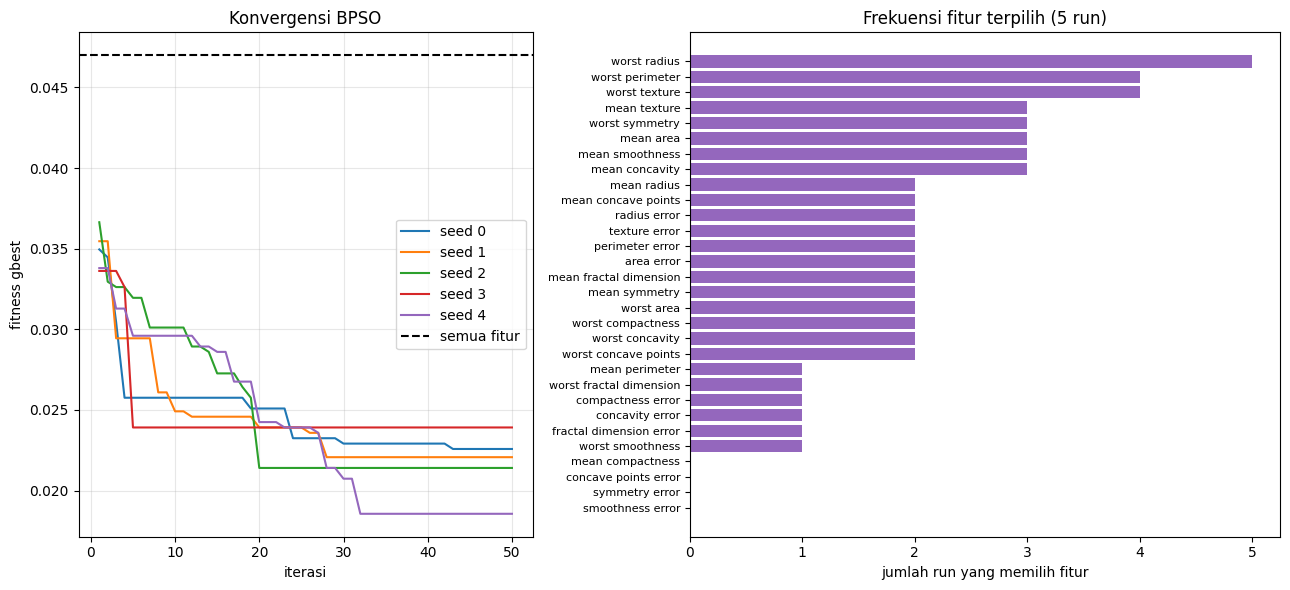

Fitur yang terpilih di >= 4 dari 5 run: ['worst radius', 'worst texture', 'worst perimeter']


In [17]:
selection_count = np.sum(bpso_masks, axis=0)                 # how many runs picked each feature
order = np.argsort(selection_count)

fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.3]})
for seed, hist in enumerate(bpso_histories):
    axes[0].plot(np.arange(1, len(hist) + 1), hist, label=f"seed {seed}")
axes[0].axhline(fitness(all_mask), color="black", linestyle="--", label="semua fitur")
axes[0].set(title="Konvergensi BPSO", xlabel="iterasi", ylabel="fitness gbest")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].barh(np.array(data.feature_names)[order], selection_count[order], color="tab:purple")
axes[1].set(title=f"Frekuensi fitur terpilih ({BPSO_RUNS} run)", xlabel="jumlah run yang memilih fitur")
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "bpso_fitur.png", dpi=150)
plt.show()

frequent = [str(name) for name, count in zip(data.feature_names, selection_count) if count >= 4]
print("Fitur yang terpilih di >= 4 dari 5 run:", frequent)

Jumlah fitur turun dari 30 menjadi rata-rata 11,6 (antara 9 dan 14). Akurasi CV data latih naik dari 96,3% ke 98,2%, tetapi akurasi data uji tidak ikut naik: semua fitur 95,6%, BPSO rata-rata 94,7%. Selisihnya hanya 1-2 sampel dari 114, jadi akurasinya hampir sama padahal fiturnya kurang dari separuh.

Akurasi CV naik tetapi data uji tidak karena subset dipilih untuk memaksimalkan CV itu sendiri, sehingga angkanya optimis. Itulah alasan data uji dipisahkan sejak awal.

Fitur yang paling sering terpilih adalah worst radius (5 dari 5 run), lalu worst perimeter dan worst texture (4 dari 5). Ini masuk akal karena fitur "worst" menggambarkan ukuran dan tekstur inti sel yang paling abnormal. Fitur lain hanya terpilih 2-3 kali, mungkin karena radius, perimeter, dan area saling berkorelasi sehingga bisa saling menggantikan. Dengan hanya 5 run dan 50 iterasi, hasil ini belum kuat dan beberapa run mungkin masih bisa membaik.

## 7. Kesimpulan

- PSO berhasil diimplementasikan dari nol dengan NumPy, dan hasilnya bisa diulang karena memakai seed.
- Sphere: semua konfigurasi sukses 100%, A tercepat dan B paling lambat.
- Rastrigin: B terbaik (mean 3,23, sukses 100%), sedangkan A dan C terjebak di minimum lokal (sukses 63% dan 83%).
- Diversitas menjelaskan hasilnya: eksplorasi di awal penting untuk fungsi multimodal, sedangkan untuk fungsi unimodal lebih baik cepat konvergen.
- C setara dengan inersia w = 0,7298 dan c = 1,496. Pola A dan C mirip, tetapi angkanya tetap berbeda signifikan.
- Bonus: BPSO mengurangi fitur dari 30 menjadi sekitar 12 dengan akurasi uji hampir sama.

In [18]:
print(f"Total waktu menjalankan notebook: {time.time() - NOTEBOOK_START:.1f} detik")

Total waktu menjalankan notebook: 46.7 detik
